## 0. Instalación y preparación del entorno

Esta primera celda prepara el entorno de trabajo para analizar imágenes con Python.

- `opencv-python-headless` instala OpenCV sin componentes gráficos de escritorio; es útil en Google Colab.
- `cv2` permite leer, transformar y analizar imágenes.
- `os` permite consultar rutas y tamaños de archivos.
- `pandas` organiza los resultados en tablas.
- `numpy` realiza operaciones numéricas y comparaciones entre matrices.
- `matplotlib.pyplot` muestra las imágenes y sus comparaciones.
- `Path` permite trabajar con rutas de archivos, aunque en las celdas actuales no se utiliza explícitamente.

Al final se imprimen las versiones de OpenCV y NumPy para identificar las bibliotecas del entorno.


In [1]:
# Instala OpenCV en una versión apropiada para entornos sin interfaz gráfica, como Google Colab.
!pip -q install opencv-python-headless

# Importa las bibliotecas necesarias para leer imágenes, manejar archivos,
# construir tablas, hacer cálculos numéricos y visualizar resultados.
import cv2
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Muestra las versiones instaladas para dejar constancia del entorno de ejecución.
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)


OpenCV: 5.0.0
NumPy: 2.3.5


## 1. Cargamos las imágenes

En esta sección se seleccionan las fotografías que se analizarán. Para cumplir la guía, segun lo recomendado se cargaron imágenes del mismo objeto bajo distintas condiciones: referencia, baja iluminación, desenfoque o movimiento, fondo complejo y otra perspectiva.


Se seleccionaron 5 imágenes.
Imágenes cargadas correctamente: 5


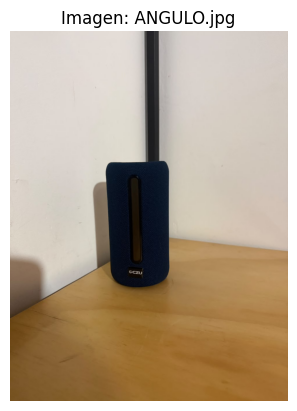

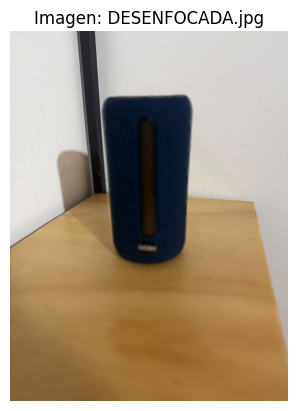

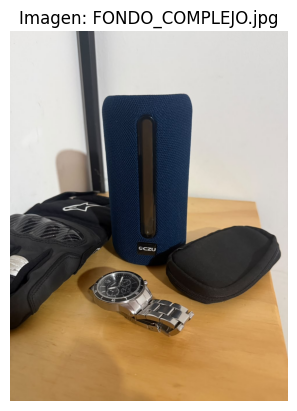

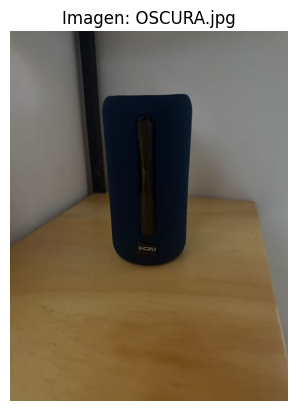

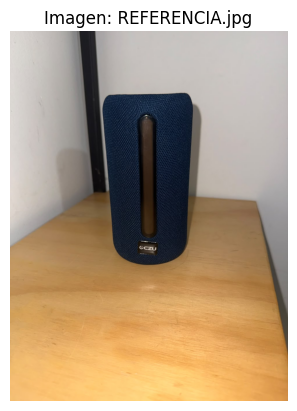

In [2]:

# Función auxiliar para mostrar una imagen usando Matplotlib.
def mostrar(imagen, titulo="Imagen"):
    """Muestra una imagen de OpenCV respetando el orden de canales BGR."""
    if imagen is None:
        print(f"No se puede mostrar '{titulo}': la imagen no está disponible.")
        return
    # OpenCV lee imágenes a color como BGR; Matplotlib espera RGB.
    if imagen.ndim == 3:
        imagen_mostrar = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
        plt.imshow(imagen_mostrar)
    else:
        # Si ya está en escala de grises, se muestra con un mapa de grises.
        plt.imshow(imagen, cmap="gray")
    plt.title(titulo)
    plt.axis("off")
    plt.show()


# Función auxiliar para crear una imagen de prueba si no se seleccionan archivos.
def crear_imagen_de_prueba(ruta="imagen_prueba.png"):
    """Crea una imagen sintética sencilla para comprobar el funcionamiento del notebook."""
    imagen_prueba = np.full((300, 400, 3), 220, dtype=np.uint8)
    cv2.rectangle(imagen_prueba, (100, 70), (300, 230), (40, 90, 180), -1)
    cv2.circle(imagen_prueba, (200, 150), 45, (40, 180, 80), -1)
    cv2.imwrite(ruta, imagen_prueba)
    print(f"Se creó una imagen sintética de prueba: {ruta}")
    return ruta


# Define una función para seleccionar archivos de imagen según el entorno de ejecución.
def seleccionar_imagenes():
    """
    Permite seleccionar varias imágenes en Google Colab o desde el escritorio.
    Devuelve una lista con las rutas de los archivos seleccionados.
    """
    # Intenta primero el selector de archivos de Google Colab.
    try:
        from google.colab import files
        print("Selecciona una o varias imágenes JPG o PNG.")
        cargados = files.upload()
        if cargados:
            rutas = list(cargados.keys())
            print(f"Se cargaron {len(rutas)} imágenes.")
            return rutas
        print("No se seleccionaron imágenes.")
        return []
    except ImportError:
        # Si no se ejecuta en Colab, se prueba el selector de escritorio.
        pass

    try:
        import tkinter as tk
        from tkinter import filedialog
        ventana = tk.Tk()
        ventana.withdraw()
        ventana.attributes("-topmost", True)
        rutas = filedialog.askopenfilenames(
            title="Selecciona una o varias imágenes",
            filetypes=[("Imágenes", "*.jpg *.jpeg *.png"), ("Todos los archivos", "*.*")]
        )
        ventana.destroy()
        rutas = list(rutas)
        print(f"Se seleccionaron {len(rutas)} imágenes." if rutas else "No se seleccionaron imágenes.")
        return rutas
    except Exception as e:
        print(f"No se pudo abrir el selector de archivos: {e}")
        return []


# Selecciona las imágenes. Si no se elige ninguna, crea una imagen sintética de prueba.
rutas_imagenes = seleccionar_imagenes()
if not rutas_imagenes:
    print("Se utilizará una imagen sintética de prueba. Para la entrega, carga tus fotografías reales.")
    rutas_imagenes = [crear_imagen_de_prueba()]

# Lee y valida cada archivo seleccionado.
imagenes = []
for ruta in rutas_imagenes:
    if not os.path.isfile(ruta):
        print(f"Archivo no encontrado: {ruta}")
        continue

    img = cv2.imread(ruta)
    if img is None:
        print(f"No se pudo leer la imagen: {ruta}")
        continue

    imagenes.append({
        "ruta": ruta,
        "nombre": os.path.basename(ruta),
        "imagen": img
    })

print(f"Imágenes cargadas correctamente: {len(imagenes)}")

# Muestra las imágenes cargadas para comprobar visualmente la selección.
for elemento in imagenes:
    mostrar(elemento["imagen"], f"Imagen: {elemento['nombre']}")


## 2. Inspección de las imágenes como datos

Una imagen digital se representa mediante una matriz de píxeles. Esta sección revisa las dimensiones, el tipo de dato, el rango de intensidades y el brillo promedio de cada fotografía. Estos valores ayudan a describir la imagen objetivamente, además de observarla visualmente.


In [3]:

# Recorre todas las imágenes cargadas para imprimir sus características básicas.
for elemento in imagenes:
    img = elemento["imagen"]  # Matriz de píxeles de la imagen actual.
    nombre = elemento["nombre"]  # Nombre del archivo, útil para identificar los resultados.

    print("-------------------------")
    print("Ruta:", elemento["nombre"])

    # shape informa las dimensiones: alto, ancho y, normalmente, número de canales.
    print("Forma (alto, ancho, canales):", elemento["imagen"].shape)

    # dtype indica cómo se representa numéricamente cada píxel (por ejemplo, uint8).
    print("Tipo de dato:", elemento["imagen"].dtype)

    # min() y max() permiten conocer el menor y el mayor valor de intensidad presente.
    print("Valor mínimo:", elemento["imagen"].min())
    print("Valor máximo:", elemento["imagen"].max())

    # Se extraen alto y ancho sin incluir el número de canales.
    alto, ancho = elemento["imagen"].shape[:2]
    print("Alto:", alto)
    print("Ancho:", ancho)

    # Consulta el píxel del centro de la imagen; en una imagen BGR devuelve sus tres intensidades.
    print("Píxel central BGR:", elemento["imagen"][alto//2, ancho//2])

    # Convierte la imagen a escala de grises para resumir la intensidad luminosa en un solo canal.
    gris = cv2.cvtColor(elemento["imagen"], cv2.COLOR_BGR2GRAY)

    # La media de intensidades sirve como estimación del brillo promedio.
    # En imágenes de 8 bits, las intensidades suelen estar entre 0 (negro) y 255 (blanco).
    brillo = gris.mean()
    print('Brillo promedio:', brillo)


-------------------------
Ruta: ANGULO.jpg
Forma (alto, ancho, canales): (1280, 960, 3)
Tipo de dato: uint8
Valor mínimo: 0
Valor máximo: 240
Alto: 1280
Ancho: 960
Píxel central BGR: [49 32 23]
Brillo promedio: 157.65074462890624
-------------------------
Ruta: DESENFOCADA.jpg
Forma (alto, ancho, canales): (1280, 960, 3)
Tipo de dato: uint8
Valor mínimo: 0
Valor máximo: 239
Alto: 1280
Ancho: 960
Píxel central BGR: [ 8 27 42]
Brillo promedio: 144.57341064453124
-------------------------
Ruta: FONDO_COMPLEJO.jpg
Forma (alto, ancho, canales): (1280, 960, 3)
Tipo de dato: uint8
Valor mínimo: 0
Valor máximo: 255
Alto: 1280
Ancho: 960
Píxel central BGR: [26 44 61]
Brillo promedio: 139.15591471354168
-------------------------
Ruta: OSCURA.jpg
Forma (alto, ancho, canales): (1280, 960, 3)
Tipo de dato: uint8
Valor mínimo: 0
Valor máximo: 163
Alto: 1280
Ancho: 960
Píxel central BGR: [ 5 16 24]
Brillo promedio: 94.30571858723958
-------------------------
Ruta: REFERENCIA.jpg
Forma (alto, ancho, c

## 3. Comparación de métricas

La siguiente celda calcula las métricas principales para cada imagen y las organiza en una tabla. El brillo aproxima la luminosidad, la desviación estándar de intensidades sirve como estimación sencilla del contraste y la varianza del Laplaciano permite comparar la nitidez relativa entre fotografías del mismo conjunto.


In [4]:
# Esta lista almacenará un registro de métricas para cada imagen.
datos_imagenes = []

# Calcula las mismas métricas para todas las fotografías, para facilitar su comparación.
for elemento in imagenes:
    img = elemento["imagen"]
    nombre = elemento["nombre"]

    # Obtiene las dimensiones espaciales de la imagen.
    alto, ancho = img.shape[:2]

    # Determina si la imagen tiene varios canales (por ejemplo, BGR) o uno solo (escala de grises).
    canales = img.shape[2] if img.ndim == 3 else 1

    # Extrae el píxel central como dato descriptivo; no representa por sí solo toda la imagen.
    pixel_central = img[alto // 2, ancho // 2]

    # BRILLO: convierte a escala de grises y calcula la intensidad media.
    gris = cv2.cvtColor(elemento["imagen"], cv2.COLOR_BGR2GRAY)
    brillo = gris.mean()

    # CONTRASTE: la desviación estándar mide cuánto varían las intensidades respecto de la media.
    # Un valor pequeño puede indicar intensidades similares; debe interpretarse junto con la imagen.
    contraste = gris.std()

    # NITIDEZ: la varianza del Laplaciano mide la presencia de cambios rápidos de intensidad/bordes.
    # Es una aproximación comparativa, no un umbral universal de calidad.
    nitidez = cv2.Laplacian(gris, cv2.CV_64F).var()

    # RESOLUCIÓN: cantidad total de píxeles, calculada como ancho por alto.
    resolucion = ancho * alto

    # Guarda las características en un diccionario para crear una tabla al finalizar el recorrido.
    datos_imagenes.append({
        "Nombre": nombre,
        "Forma (alto, ancho, canales)": str(img.shape),
        "Tipo de dato": str(img.dtype),
        "Valor mínimo": int(img.min()),
        "Valor máximo": int(img.max()),
        "Alto (px)": alto,
        "Ancho (px)": ancho,
        "Canales": canales,
        "Píxel central BGR/Gris": str(pixel_central.tolist()
                                      if hasattr(pixel_central, "tolist")
                                      else pixel_central),
        "Brillo": brillo,
        "Contraste": contraste,
        "Nitidez": nitidez,
        "Resolución": resolucion
    })

# Convierte la lista de diccionarios en un DataFrame de pandas, una tabla con columnas y filas.
tabla_imagenes = pd.DataFrame(datos_imagenes)

# Presenta la tabla para comparar las métricas entre fotografías.
display(tabla_imagenes)


,Nombre,"Forma (alto, ancho, canales)",Tipo de dato,Valor mínimo,Valor máximo,Alto (px),Ancho (px),Canales,Píxel central BGR/Gris,Brillo,Contraste,Nitidez,Resolución
0,ANGULO.jpg,"(1280, 960, 3)",uint8,0,240,1280,960,3,"[49, 32, 23]",157.650745,60.542117,31.985278,1228800
1,DESENFOCADA.jpg,"(1280, 960, 3)",uint8,0,239,1280,960,3,"[8, 27, 42]",144.573411,65.200021,14.305587,1228800
2,FONDO_COMPLEJO.jpg,"(1280, 960, 3)",uint8,0,255,1280,960,3,"[26, 44, 61]",139.155915,76.334006,185.543351,1228800
3,OSCURA.jpg,"(1280, 960, 3)",uint8,0,163,1280,960,3,"[5, 16, 24]",94.305719,37.601619,10.182681,1228800
4,REFERENCIA.jpg,"(1280, 960, 3)",uint8,0,255,1280,960,3,"[20, 39, 60]",148.881464,58.921319,139.929468,1228800


## 4. Formato y tamaño de archivo

Esta sección guarda la imagen de referencia en JPEG y PNG para comparar el tamaño de ambos archivos y comprobar si los píxeles guardados coinciden con los de la imagen de origen.

JPEG utiliza compresión con pérdida, mientras que PNG utiliza compresión sin pérdida. Por ello, el tamaño puede cambiar aunque la resolución sea la misma. La comparación numérica depende de que la variable utilizada para representar la imagen original corresponda realmente a la imagen de referencia.


In [5]:

# Busca explícitamente la imagen de referencia usando el nombre sin distinguir mayúsculas/minúsculas.
# También acepta extensiones .jpg, .jpeg y .png.
img_referencia = None
for elemento in imagenes:
    nombre_sin_extension = os.path.splitext(elemento["nombre"])[0].casefold()
    if nombre_sin_extension == "referencia":
        img_referencia = elemento["imagen"]
        break

# Si no hay una imagen llamada referencia, utiliza la primera imagen cargada como alternativa.
if img_referencia is None and imagenes:
    img_referencia = imagenes[0]["imagen"]
    print(f"No se encontró un archivo llamado 'referencia'; se usará '{imagenes[0]['nombre']}'.")

if img_referencia is None:
    raise ValueError("No hay imágenes válidas para comparar. Carga al menos una imagen antes de continuar.")

# Guarda la misma imagen de referencia en JPEG y PNG.
# JPEG usa compresión con pérdida; PNG usa compresión sin pérdida.
cv2.imwrite("comparacion.jpg", img_referencia, [cv2.IMWRITE_JPEG_QUALITY, 90])
cv2.imwrite("comparacion.png", img_referencia)

# Lee de nuevo los archivos para analizar lo que quedó guardado.
img_jpg = cv2.imread("comparacion.jpg")
img_png = cv2.imread("comparacion.png")

# Calcula el tamaño de los archivos en bytes.
tamano_jpeg = os.path.getsize("comparacion.jpg")
tamano_png = os.path.getsize("comparacion.png")
print("Tamaño JPEG:", tamano_jpeg, "bytes")
print("Tamaño PNG:", tamano_png, "bytes")

# Compara los píxeles guardados contra la misma imagen de referencia.
jpeg_igual = np.array_equal(img_referencia, img_jpg)
png_igual = np.array_equal(img_referencia, img_png)
print("JPEG idéntico a original:", jpeg_igual)
print("PNG idéntico a original:", png_igual)

# Calcula el error absoluto medio. Un valor de cero significa que no hay diferencias entre matrices.
error_jpeg = np.mean(np.abs(img_referencia.astype(np.float32) - img_jpg.astype(np.float32)))
error_png = np.mean(np.abs(img_referencia.astype(np.float32) - img_png.astype(np.float32)))
print("Error medio JPEG:", error_jpeg)
print("Error medio PNG:", error_png)

# Calcula la resolución como ancho por alto; los canales no se multiplican en esta métrica.
alto_jpeg, ancho_jpeg = img_jpg.shape[:2]
alto_png, ancho_png = img_png.shape[:2]
resolucion_jpeg = ancho_jpeg * alto_jpeg
resolucion_png = ancho_png * alto_png
print("Resolución JPG:", resolucion_jpeg)
print("Resolución PNG:", resolucion_png)

# Presenta una tabla con los resultados obtenidos en esta ejecución.
tabla_formatos = pd.DataFrame([
    {
        "Formato": "JPEG",
        "Tamaño del archivo (bytes)": tamano_jpeg,
        "Idéntico a la referencia": jpeg_igual,
        "Error medio": error_jpeg,
        "Resolución (píxeles)": resolucion_jpeg
    },
    {
        "Formato": "PNG",
        "Tamaño del archivo (bytes)": tamano_png,
        "Idéntico a la referencia": png_igual,
        "Error medio": error_png,
        "Resolución (píxeles)": resolucion_png
    }
])
display(tabla_formatos)


Tamaño JPEG: 119952 bytes
Tamaño PNG: 1067412 bytes
JPEG idéntico a original: False
PNG idéntico a original: True
Error medio JPEG: 0.26032716
Error medio PNG: 0.0
Resolución JPG: 1228800
Resolución PNG: 1228800


,Formato,Tamaño del archivo (bytes),Idéntico a la referencia,Error medio,Resolución (píxeles)
0,JPEG,119952,False,0.260327,1228800
1,PNG,1067412,True,0.000000,1228800


## 5. Tratamiento de una imagen problemática

La imagen elegida es la fotografía oscura. Se aplicará un ajuste de brillo y contraste para mejorar su luminosidad y separar mejor algunas intensidades.

La transformación se debe evaluar con las métricas y la comparación visual antes/después. Aumentar una métrica no garantiza por sí solo que la imagen sea mejor: también hay que comprobar que no se pierdan detalles ni se saturen zonas claras.


,Métrica,Antes,Después,Cambio (después - antes)
0,Brillo promedio,9.430572e+01,1.608926e+02,66.586915
1,Contraste (desviación estándar),3.760162e+01,6.017833e+01,22.576710
2,Nitidez (varianza del Laplaciano),1.018268e+01,2.659777e+01,16.415090
3,Resolución (píxeles),1.228800e+06,1.228800e+06,0.000000


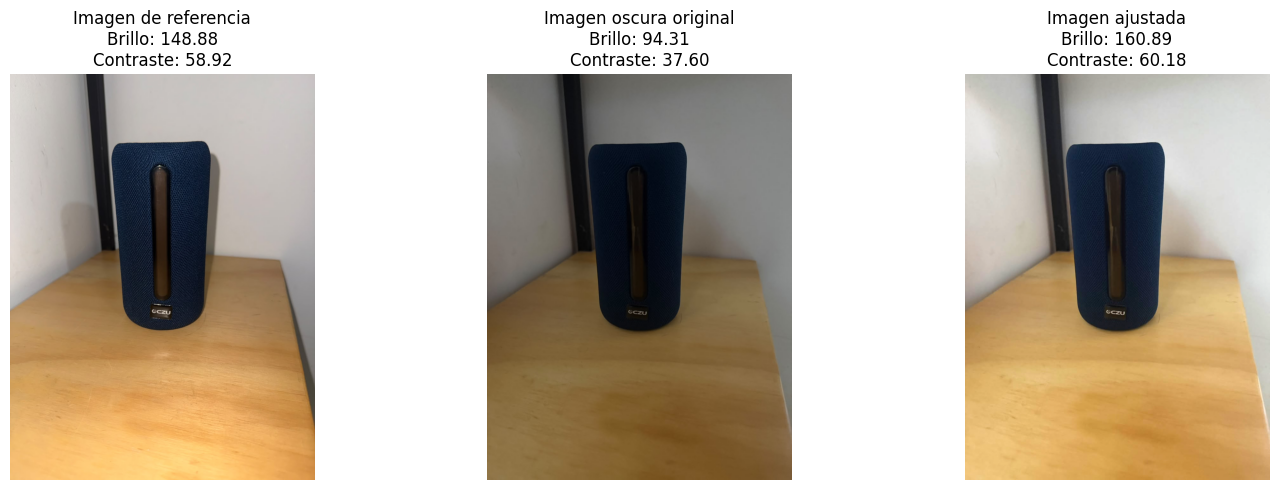

In [6]:

# Inicializa las variables para evitar referencias accidentales a imágenes inexistentes.
img_tratamiento = None
img_referencia = None

# Busca los archivos por nombre sin distinguir mayúsculas/minúsculas ni extensión.
for elemento in imagenes:
    nombre_base = os.path.splitext(elemento["nombre"])[0].casefold()
    if nombre_base == "oscura":
        img_tratamiento = elemento["imagen"]
    elif nombre_base == "referencia":
        img_referencia = elemento["imagen"]

# Si no existe un archivo llamado 'oscura', informa el problema claramente.
if img_tratamiento is None:
    raise ValueError("No se encontró una imagen llamada 'oscura'. Carga el archivo oscura.jpg/png.")
# Si no existe la referencia, usa la imagen oscura como referencia visual para que el código pueda continuar.
if img_referencia is None:
    print("Aviso: no se encontró una imagen llamada 'referencia'; se usará la imagen oscura como referencia visual.")
    img_referencia = img_tratamiento.copy()

# Define los parámetros de la transformación.
factor_contraste = 1.6  # alpha mayor que 1 aumenta la separación entre intensidades.
ajuste_brillo = 10       # beta positivo suma intensidad y aclara la imagen.

# Aplica la transformación lineal: píxel_nuevo = alpha * píxel_original + beta.
# OpenCV limita el resultado al rango válido de una imagen de 8 bits (0 a 255).
img_ajustada = cv2.convertScaleAbs(
    img_tratamiento,
    alpha=factor_contraste,
    beta=ajuste_brillo
)

# Función que calcula las métricas requeridas para una imagen.
def calcular_metricas(imagen):
    """Devuelve brillo, contraste, nitidez y resolución de una imagen."""
    gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
    alto, ancho = gris.shape[:2]
    return {
        "Brillo promedio": gris.mean(),
        "Contraste (desviación estándar)": gris.std(),
        "Nitidez (varianza del Laplaciano)": cv2.Laplacian(gris, cv2.CV_64F).var(),
        "Resolución (píxeles)": int(ancho * alto)
    }

# Calcula las métricas antes y después del tratamiento para comprobar los cambios.
metricas_antes = calcular_metricas(img_tratamiento)
metricas_despues = calcular_metricas(img_ajustada)
metricas_referencia = calcular_metricas(img_referencia)

# Organiza los valores en una tabla comparativa.
tabla_antes_despues = pd.DataFrame({
    "Métrica": list(metricas_antes.keys()),
    "Antes": list(metricas_antes.values()),
    "Después": list(metricas_despues.values())
})
tabla_antes_despues["Cambio (después - antes)"] = (
    tabla_antes_despues["Después"] - tabla_antes_despues["Antes"]
)
display(tabla_antes_despues)

# Muestra referencia, imagen original problemática e imagen ajustada lado a lado.
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img_referencia, cv2.COLOR_BGR2RGB))
plt.title(f"Imagen de referencia\nBrillo: {metricas_referencia['Brillo promedio']:.2f}"
          f"\nContraste: {metricas_referencia['Contraste (desviación estándar)']:.2f}")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(img_tratamiento, cv2.COLOR_BGR2RGB))
plt.title(f"Imagen oscura original\nBrillo: {metricas_antes['Brillo promedio']:.2f}"
          f"\nContraste: {metricas_antes['Contraste (desviación estándar)']:.2f}"
)
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(img_ajustada, cv2.COLOR_BGR2RGB))
plt.title(
    f"Imagen ajustada\nBrillo: {metricas_despues['Brillo promedio']:.2f}"
    f"\nContraste: {metricas_despues['Contraste (desviación estándar)']:.2f}"
)
plt.axis("off")

plt.tight_layout()
plt.show()


### 5.1 Ecualización del histograma

En esta sección se convierte la imagen oscura a escala de grises y se aplica la ecualización del histograma. La técnica redistribuye las intensidades para intentar mejorar el contraste global. Después se comparan visualmente la imagen original y la ecualizada. La ecualización no recupera información que no fue capturada y puede amplificar el ruido, por lo que el resultado debe evaluarse visualmente.

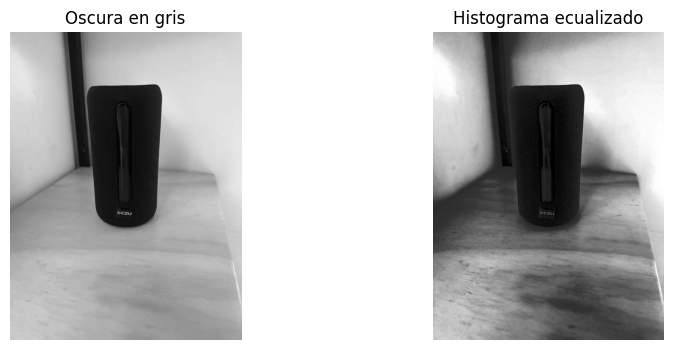

In [7]:
# Convertir la imagen problemática a escala de grises para trabajar con un único canal de intensidad.
# Esto simplifica la ecualización, ya que cv2.equalizeHist espera una imagen de un solo canal.
gris = cv2.cvtColor(img_tratamiento, cv2.COLOR_BGR2GRAY)

# Ecualizar el histograma para redistribuir los niveles de intensidad y mejorar el contraste global.
# Es útil cuando las intensidades están concentradas en una zona limitada del rango de grises.
# La ecualización puede hacer más visibles algunos detalles, aunque también puede amplificar el ruido.
ecualizada = cv2.equalizeHist(gris)

# Crear una figura con dos paneles para comparar la imagen antes y después del tratamiento.
plt.figure(figsize=(10, 4))

# Mostrar la imagen original en escala de grises.
plt.subplot(1, 2, 1)
plt.imshow(gris, cmap="gray")
plt.title("Oscura en gris")
plt.axis("off")  # Ocultar los ejes para centrar la atención en la imagen.

# Mostrar la imagen después de la ecualización del histograma.
plt.subplot(1, 2, 2)
plt.imshow(ecualizada, cmap="gray")
plt.title("Histograma ecualizado")
plt.axis("off")

# Ajustar y mostrar la comparación.
plt.show()

### 5.2 Detección de bordes con Canny

Se suavizan las imágenes con un filtro Gaussiano para reducir ruido y después se utiliza Canny para localizar cambios intensos de luminosidad. Los bordes ayudan a estudiar los contornos, pero no constituyen por sí solos una máscara de extracción del objeto.

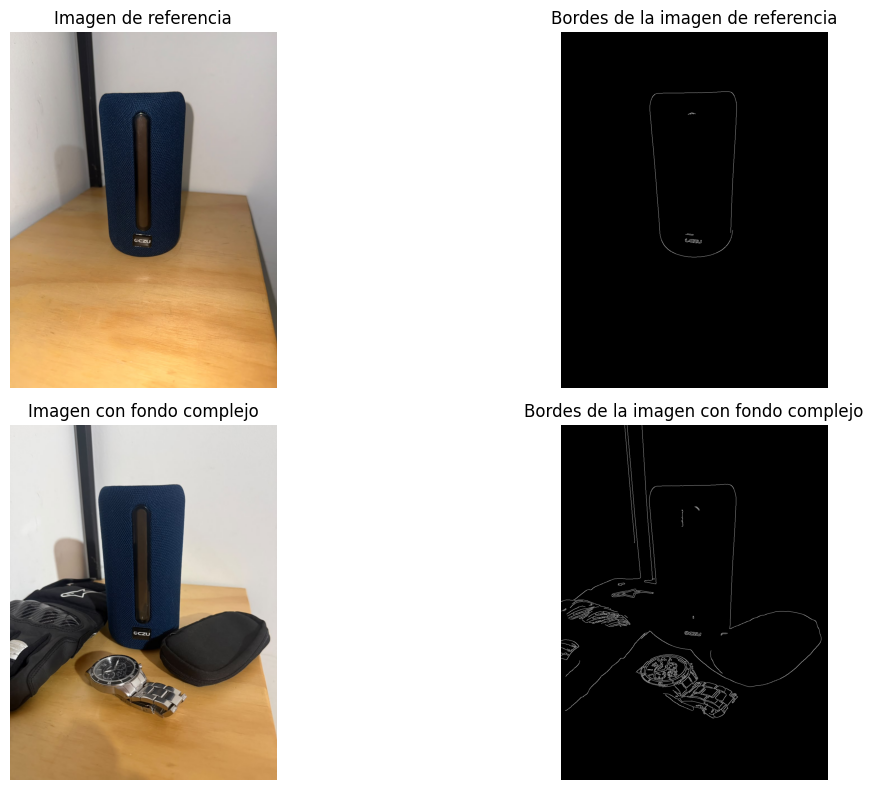

In [8]:
# Inicializar la variable donde se almacenará la imagen con fondo complejo.
img_compleja = None

# Buscar la imagen por el nombre base, ignorando mayúsculas/minúsculas y la extensión.
for elemento in imagenes:
    nombre_base = os.path.splitext(elemento["nombre"])[0].casefold()

    if nombre_base == "fondo_complejo":
        img_compleja = elemento["imagen"]
        break  # Detener la búsqueda cuando se encuentre el archivo.

# Comprobar que la imagen se haya cargado correctamente.
if img_compleja is None:
    raise ValueError("No se encontró una imagen llamada fondo_complejo.")

# Convertir la imagen de fondo complejo y la referencia a escala de grises.
# Así se analizan las variaciones de intensidad sin considerar los colores.
gris_compleja = cv2.cvtColor(img_compleja, cv2.COLOR_BGR2GRAY)
gris_referencia = cv2.cvtColor(img_referencia, cv2.COLOR_BGR2GRAY)

# Aplicar un desenfoque Gaussiano leve para reducir ruido antes de detectar bordes.
# El kernel (5, 5) define el tamaño de la ventana; sigma=0 deja que OpenCV lo calcule.
suavizada = cv2.GaussianBlur(gris_compleja, (5, 5), 0)
suavizada_referencia = cv2.GaussianBlur(gris_referencia, (5, 5), 0)

# Detectar bordes con Canny. Los umbrales determinan qué gradientes se consideran bordes.
# Valores distintos pueden producir cantidades diferentes de contornos.
bordes = cv2.Canny(suavizada, 50, 150)
bordes_referencia = cv2.Canny(suavizada_referencia, 100, 500)

# Crear una figura de cuatro paneles para comparar imágenes originales y sus bordes.
plt.figure(figsize=(14, 8))

# Mostrar la imagen de referencia en color.
plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(img_referencia, cv2.COLOR_BGR2RGB))
plt.title("Imagen de referencia")
plt.axis("off")

# Mostrar los bordes encontrados en la referencia.
plt.subplot(2, 2, 2)
plt.imshow(bordes_referencia, cmap="gray")
plt.title("Bordes de la imagen de referencia")
plt.axis("off")

# Mostrar la imagen con fondo complejo en color.
plt.subplot(2, 2, 3)
plt.imshow(cv2.cvtColor(img_compleja, cv2.COLOR_BGR2RGB))
plt.title("Imagen con fondo complejo")
plt.axis("off")

# Mostrar los bordes detectados en la imagen con fondo complejo.
plt.subplot(2, 2, 4)
plt.imshow(bordes, cmap="gray")
plt.title("Bordes de la imagen con fondo complejo")
plt.axis("off")

# Evitar que los títulos y paneles se superpongan.
plt.tight_layout()
plt.show()

# Nota: la detección de bordes resalta límites, pero no extrae automáticamente el objeto.
# Para ello se requiere un método de segmentación o una máscara.

### 5.3 Contornos y cajas delimitadoras

`findContours` identifica curvas en la imagen binaria de bordes y `boundingRect` calcula una caja rectangular alrededor de cada contorno. Las coordenadas están expresadas en píxeles y corresponden a la imagen cuyos bordes se analizaron. El filtro de área controla qué contornos se dibujan.

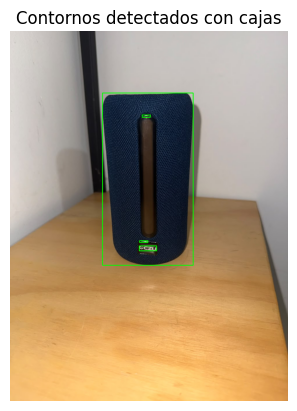

Cantidad de contornos detectados: 4
Cantidad de contornos filtrados: 4
Áreas filtradas: [463.5, 2.0, 15.0, 100.0]


In [9]:
# Buscar contornos externos en la imagen de bordes de referencia.
# RETR_EXTERNAL devuelve únicamente los contornos exteriores y CHAIN_APPROX_SIMPLE
# reduce los puntos almacenados para representar cada contorno.
contornos, _ = cv2.findContours(
    bordes_referencia, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

# Crear una copia de la imagen de referencia para dibujar sin modificar el original.
resultado = img_referencia.copy()

# Lista para registrar las áreas de los contornos que pasan el filtro.
areas = []

# Recorrer cada contorno detectado.
for c in contornos:
    # Calcular el área encerrada por el contorno, medida en píxeles cuadrados.
    area = cv2.contourArea(c)

    # Conservar contornos menores de 500 píxeles cuadrados.
    # Este umbral determina qué detalles se dibujan; ajústalo según el objeto y la imagen.
    if area < 500:
        # Obtener la caja delimitadora: x e y son la esquina superior izquierda;
        # w es el ancho y h es el alto del rectángulo.
        x, y, w, h = cv2.boundingRect(c)

        # Dibujar el rectángulo verde alrededor del contorno seleccionado.
        cv2.rectangle(resultado, (x, y), (x + w, y + h), (0, 255, 0), 2)

        # Guardar el área para poder revisar los contornos seleccionados.
        areas.append(area)

# Mostrar la imagen con las cajas dibujadas.
mostrar(resultado, "Contornos detectados con cajas")

# Informar cuántos contornos se encontraron en total y cuántos pasaron el filtro.
print("Cantidad de contornos detectados:", len(contornos))
print("Cantidad de contornos filtrados:", len(areas))
print("Áreas filtradas:", areas[:10])

# Importante: este filtro conserva contornos pequeños (área < 500).
# Si deseas seleccionar el contorno principal del objeto, probablemente necesites area > 500
# o seleccionar la caja más grande; verifica el resultado visual antes de decidir.

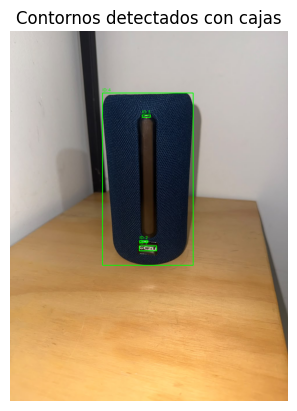

Cantidad de rectángulos: 4
Rectángulo 1: x=446, y=743, ancho=60, alto=17, área=464
Rectángulo 2: x=447, y=725, ancho=29, alto=6, área=2
Rectángulo 3: x=456, y=290, ancho=28, alto=8, área=15
Rectángulo 4: x=319, y=214, ancho=313, alto=596, área=100


In [10]:
# Encontrar los contornos externos de la imagen de bordes de referencia.
contornos, _ = cv2.findContours(
    bordes_referencia,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Copiar la referencia para dibujar rectángulos sin alterar la imagen original.
resultado = img_referencia.copy()

# Crear una lista para guardar las coordenadas y dimensiones de cada rectángulo detectado.
rectangulos = []

# Enumerar los contornos para asignar un identificador a cada uno.
for i, c in enumerate(contornos):
    # Calcular el área del contorno en píxeles cuadrados.
    area = cv2.contourArea(c)

    # Este filtro selecciona contornos pequeños. Cambiar a area > 500 si se buscan
    # contornos grandes; el criterio correcto depende de la imagen y del objeto.
    if area < 500:
        # Obtener la esquina superior izquierda (x, y) y las dimensiones (ancho, alto).
        x, y, w, h = cv2.boundingRect(c)

        # Guardar las coordenadas iniciales/finales, dimensiones y área del rectángulo.
        rectangulos.append({
            "id": i + 1,
            "x": x,
            "y": y,
            "ancho": w,
            "alto": h,
            "area": area,
            "x_final": x + w,
            "y_final": y + h
        })

        # Dibujar el rectángulo verde sobre la copia de la imagen.
        cv2.rectangle(
            resultado,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        # Escribir el identificador junto al rectángulo, evitando que el texto quede fuera por arriba.
        cv2.putText(
            resultado,
            f"ID: {i + 1}",
            (x, max(y - 5, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 255, 0),
            1
        )

# Mostrar los contornos seleccionados y sus cajas delimitadoras.
mostrar(resultado, "Contornos detectados con cajas")

# Imprimir la cantidad de rectángulos guardados.
print("Cantidad de rectángulos:", len(rectangulos))

# Mostrar las coordenadas y dimensiones de cada rectángulo.
for r in rectangulos:
    print(
        f"Rectángulo {r['id']}: "
        f"x={r['x']}, y={r['y']}, "
        f"ancho={r['ancho']}, alto={r['alto']}, "
        f"área={r['area']:.0f}"
    )

# Nota: estas coordenadas pertenecen a la imagen de referencia, porque se procesó bordes_referencia.

### 5.4 Segmentación del objeto con GrabCut

GrabCut intenta separar el primer plano del fondo a partir de un rectángulo inicial. La máscara resultante se utiliza como canal alfa para que el fondo sea transparente. El rectángulo debe ajustarse a la imagen real y el resultado debe revisarse, ya que el algoritmo puede conservar partes del fondo o eliminar partes del objeto.

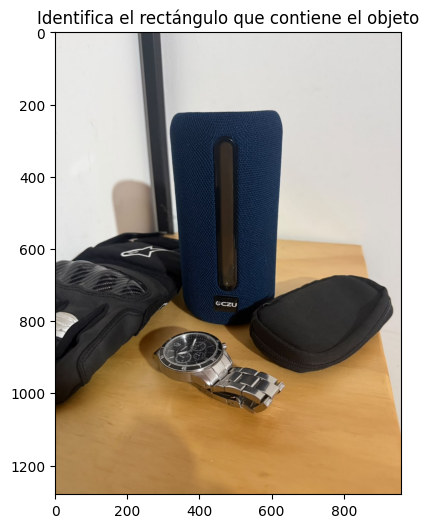

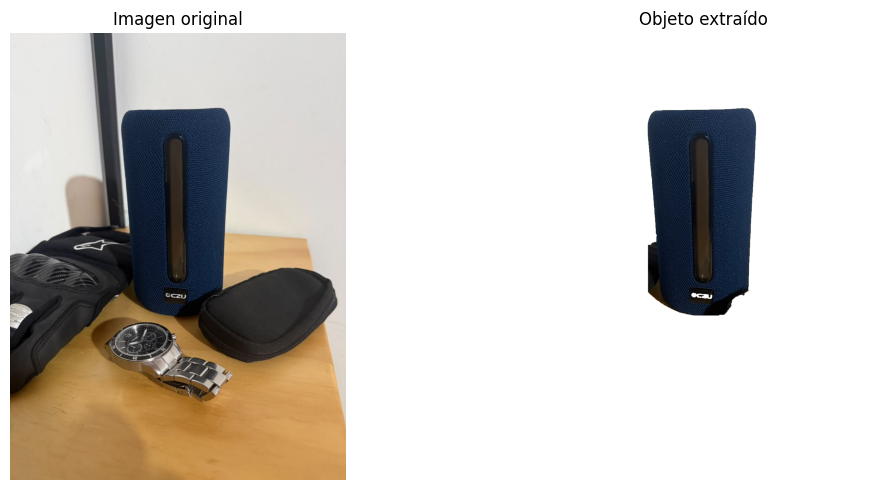

True

In [11]:
# Copiar la imagen con fondo complejo; la copia se utilizará para la segmentación.
imagen = img_compleja.copy()

# Mostrar la imagen para comprobar visualmente dónde se encuentra el objeto.
plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
plt.title("Identifica el rectángulo que contiene el objeto")
plt.axis("on")
plt.show()

# Definir un rectángulo aproximado alrededor del objeto que se desea conservar.
# x e y indican la esquina superior izquierda; ancho y alto definen sus dimensiones.
# Estos valores deben ajustarse a la resolución y a la posición del objeto en img_compleja.
x, y, ancho, alto = 319, 214, 313, 596

# Obtener las dimensiones de la imagen para comprobar que el rectángulo sea válido.
alto_img, ancho_img = imagen.shape[:2]

# Detener el proceso si el rectángulo tiene valores inválidos o se sale de la imagen.
if (x < 0 or y < 0 or ancho <= 0 or alto <= 0
        or x + ancho > ancho_img or y + alto > alto_img):
    raise ValueError("El rectángulo está fuera de los límites de la imagen.")

# Inicializar la máscara de GrabCut y los modelos estadísticos de fondo y objeto.
mascara = np.zeros(imagen.shape[:2], dtype=np.uint8)
modelo_fondo = np.zeros((1, 65), dtype=np.float64)
modelo_objeto = np.zeros((1, 65), dtype=np.float64)

# Ejecutar GrabCut para separar el primer plano del fondo usando el rectángulo inicial.
# El algoritmo refina la clasificación durante cinco iteraciones.
cv2.grabCut(
    imagen,
    mascara,
    (x, y, ancho, alto),
    modelo_fondo,
    modelo_objeto,
    5,
    cv2.GC_INIT_WITH_RECT
)

# Convertir las etiquetas de GrabCut en una máscara binaria:
# 255 representa píxeles clasificados como objeto probable/seguro y 0 como fondo.
mascara_objeto = np.where(
    (mascara == cv2.GC_FGD) | (mascara == cv2.GC_PR_FGD),
    255,
    0
).astype(np.uint8)

# Cerrar pequeñas discontinuidades en la máscara mediante una operación morfológica.
# El kernel de 3x3 define el vecindario utilizado para el cierre.
kernel = np.ones((3, 3), np.uint8)
mascara_objeto = cv2.morphologyEx(
    mascara_objeto, cv2.MORPH_CLOSE, kernel
)

# Convertir la imagen de BGR a BGRA para añadir un canal alfa de transparencia.
imagen_rgba = cv2.cvtColor(imagen, cv2.COLOR_BGR2BGRA)

# Asignar la máscara al canal alfa: el objeto queda opaco y el fondo transparente.
imagen_rgba[:, :, 3] = mascara_objeto

# Preparar una comparación visual entre la imagen original y la segmentación.
plt.figure(figsize=(12, 5))

# Mostrar la imagen completa original.
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
plt.title("Imagen original")
plt.axis("off")

# Mostrar la imagen resultante interpretando correctamente sus canales BGRA/RGBA.
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(imagen_rgba, cv2.COLOR_BGRA2RGBA))
plt.title("Objeto extraído")
plt.axis("off")

plt.tight_layout()
plt.show()

# Guardar como PNG porque este formato conserva el canal alfa de transparencia.
cv2.imwrite("objeto_extraido.png", imagen_rgba)

# GrabCut utiliza el rectángulo como orientación inicial; no utiliza automáticamente
# la imagen de referencia para reconocer el objeto. Revisa los bordes de la máscara
# y ajusta el rectángulo o la máscara si quedan partes del fondo o faltan partes del objeto.